# Neuron Migration - Rules of t0 and t1

How the rules of the first two tasks were found, and the evidence for each of them. The method is the same for
every task:

1. Write the simplest rule from the task description.
2. Mark the values where it differs from the target.
3. Let the **rule finder** (a shallow decision tree, `tools/rule_finder.py`) show which conditions separate the
   wrong values from the right ones.
4. Turn the condition into code and repeat.

# Import libraries

In [1]:
import sys
import pathlib
import pandas as pd
import matplotlib.pyplot as plt
from dateutil.relativedelta import relativedelta

sys.path.insert(0, '..')
from legacy_loader import LegacyData, valid_on
from business_calendar import is_business_day, holidays
from commission import commission
from schedule import next_due_dates, due_dates, FREQUENCY_MONTHS
from tools.rule_finder import find_rules, plot_wrong_over_time

pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 30)

# Hyperparameters

In [2]:
project_folder = pathlib.Path('../../..').resolve()

legacy_dir = project_folder / 'legacy'

targets_dir = project_folder / 'targets'

cache_dir = project_folder / '.cache'

extract_date = pd.Timestamp('2026-06-30').date()

In [3]:
data = LegacyData(legacy_dir, cache_dir=cache_dir)

# Business calendar

Collection dates (t1), trade dates and price dates (t3) need the business days of NeuralWave Life, also in the
future. The fund prices are published on every business day, so every weekday **without** a price is a holiday.
They follow the public holidays of Ticino:

- fixed: 1.1., 6.1., 19.3., 1.5., 29.6., 1.8., 15.8., 1.11., 8.12., 25.12., 26.12.
- after Easter: Easter Monday (+1), Ascension (+39), Whit Monday (+50), Corpus Christi (+60). Good Friday is a
  normal business day.

`business_calendar.py` writes this as a rule, so it also works for 2027. The check against 33 years of prices:

In [4]:
price_days = set(pd.to_datetime(data.table('NRFPRC').FP_PRCDT.unique()).date)
weekdays = pd.bdate_range(min(price_days), max(price_days)).date

predicted = {day for day in weekdays if is_business_day(day)}
print('business days without prices:', len(predicted - price_days))
print('price days that are not business days:', len(price_days - predicted))
print('holidays 2027:', sorted(holidays(2027)))

business days without prices: 0
price days that are not business days: 0
holidays 2027: [datetime.date(2027, 1, 1), datetime.date(2027, 1, 6), datetime.date(2027, 3, 19), datetime.date(2027, 3, 29), datetime.date(2027, 5, 1), datetime.date(2027, 5, 6), datetime.date(2027, 5, 17), datetime.date(2027, 5, 27), datetime.date(2027, 6, 29), datetime.date(2027, 8, 1), datetime.date(2027, 8, 15), datetime.date(2027, 11, 1), datetime.date(2027, 12, 8), datetime.date(2027, 12, 25), datetime.date(2027, 12, 26)]


# t0 Commission

## First rule

"The commission is a percentage of the received premium amount": count every item with money received.

In [5]:
targets_t0 = pd.read_csv(targets_dir / 't0_commission.csv')
premiums = data.table('NRPREM')
premiums = premiums[premiums.PR_POLNR.isin(set(targets_t0.policy_id))]

counted = premiums.set_index(['PR_POLNR', 'PR_DUENR']).index.isin(targets_t0.set_index(['policy_id', 'due_nr']).index)
wrong = pd.Series((premiums.PR_AMTRC > 0).values != counted, index=premiums.index)

rules = find_rules(premiums[['PR_STATE', 'PR_DUEDT', 'PR_AMTRC']], wrong)

5816 of 238344 values wrong (2.44%)
|--- PR_STATE_R <= 0.50
|   |--- class: right
|--- PR_STATE_R >  0.50
|   |--- PR_AMTRC <= 52.50
|   |   |--- class: wrong
|   |--- PR_AMTRC >  52.50
|   |   |--- class: wrong



The tree needs one split: items in state `R` (direct debit returned by the bank) have money received, but earn no
commission. Counting only the paid items (`P`) gives exactly the target items.

In [6]:
pd.crosstab(premiums.PR_STATE.map(data.codes('PRSTAT')), counted, colnames=['counted'])

counted,False,True
PR_STATE,,
direct debit returned,5816,0
open,3614,0
paid,0,225858
written off,3056,0


## Rate, broker and rounding

The rate comes from `NRCOMR` with the tier of the broker and the premium type of the tariff key. Testing the
choices that are open:

| Choice | Options | Wrong rows |
|---|---|---|
| Broker of the policy version valid on | money date / due date | 10 / 12 |
| Rounding | half up / half even / down | 10 / 11 / 12 |

So: broker on the **money date** (a broker change moves the commission from that day), rounded **half up**.

In [7]:
calculated = commission(data)
target = dict(zip(zip(targets_t0.policy_id, targets_t0.due_nr), targets_t0.amount))
differences = [(key, target[key], float(calculated.get(key, 0))) for key in target
               if abs(target[key] - float(calculated.get(key, 0))) > 0.001]
print(f'{len(target) - len(differences)} of {len(target)} right')
pd.DataFrame(differences, columns=['key', 'target', 'calculated'])

225848 of 225858 right


,key,target,calculated
0,"(BL10000237, 41)",49.40,5.40
1,"(BL10001299, 103)",79.70,5.70
2,"(BL10001328, 1)",936.00,859.00
3,"(BL10001567, 6)",28.50,1.50
4,"(BL10002438, 11)",310.40,242.40
5,"(BL10002462, 5)",101.80,85.80
6,"(BL10003175, 247)",20.70,11.70
7,"(BL10004049, 6)",75.15,39.15
8,"(BL10004554, 35)",16.10,5.10
9,"(BL10004722, 1)",823.00,789.00


The 10 remaining values follow no pattern (49.40 instead of 5.40, 936.00 instead of 859.00). Six are listed in
`NREXCP` as manual corrections, the other four are corrections that nobody listed: they are outliers for t5.

In [8]:
corrections = data.table('NREXCP')
listed = set(corrections[corrections.EX_TARGET.str.startswith('t0')].EX_POLNR)
pd.DataFrame([(key[0], key[0] in listed) for key, _, _ in differences], columns=['policy', 'listed in NREXCP'])

,policy,listed in NREXCP
0,BL10000237,True
1,BL10001299,False
2,BL10001328,False
3,BL10001567,True
4,BL10002438,False
5,BL10002462,True
6,BL10003175,True
7,BL10004049,True
8,BL10004554,False
9,BL10004722,True


# t1 Next due dates

## Collection date

Direct debits (`LS`) are collected on the next business day, bank transfers (`UB`) on the due date itself.

In [9]:
targets_t1 = pd.read_csv(targets_dir / 't1_next_due_dates.csv', parse_dates=['due_date', 'collection_date'])
policies = valid_on(data.table('NRPOLH'), 'PH', '2026-06-30', ['PH_POLNR']).set_index('PH_POLNR')
targets_t1['payment'] = targets_t1.policy_id.map(policies.PH_PAYMT)
targets_t1['lag_days'] = (targets_t1.collection_date - targets_t1.due_date).dt.days
pd.crosstab(targets_t1.payment, targets_t1.lag_days)

lag_days,0,1,2,3
payment,,,,
LS,8446,1269,2120,673
UB,2520,0,0,0


## Due dates

The first rule: the start date plus whole periods (the day is cut in short months). The rule finder looks at the
policies where this schedule is wrong.

In [10]:
def anchored_schedule(policy):
    begin, end = policy.PH_BEGDT.date(), policy.PH_ENDDT.date()
    months = FREQUENCY_MONTHS[policy.PH_FREQ]
    dates, periods = [], 0
    while (due := begin + relativedelta(months=months * periods)) <= extract_date + relativedelta(years=1):
        if extract_date < due < end:
            dates.append(due)
        periods += 1
    return dates

target_dates = targets_t1.groupby('policy_id').due_date.apply(lambda dates: list(dates.dt.date))
in_force = policies.loc[target_dates.index]
wrong = pd.Series([anchored_schedule(policy) != target_dates[policy.Index] for policy in in_force.itertuples()],
                  index=in_force.index)

features = in_force[['PH_APPDT', 'PH_BEGDT', 'PH_FREQ', 'PH_PRDCD']].assign(BEGIN_DAY=in_force.PH_BEGDT.dt.day)
rules = find_rules(features, wrong)

27 of 1648 values wrong (1.64%)
|--- BEGIN_DAY <= 28.50
|   |--- class: right
|--- BEGIN_DAY >  28.50
|   |--- PH_BEGDT <= 2006.99
|   |   |--- PH_FREQ_M <= 0.50
|   |   |   |--- class: wrong
|   |   |--- PH_FREQ_M >  0.50
|   |   |   |--- class: wrong
|   |--- PH_BEGDT >  2006.99
|   |   |--- class: right



Only policies that start on the 29th, 30th or 31st **before 2007** are wrong. 2007 is the year of the system
conversion (event 800 on 2007-08-11). The past due dates show what COBOL did: it added one month to the
**previous** due date, so once a short month cut the day, it stayed cut.

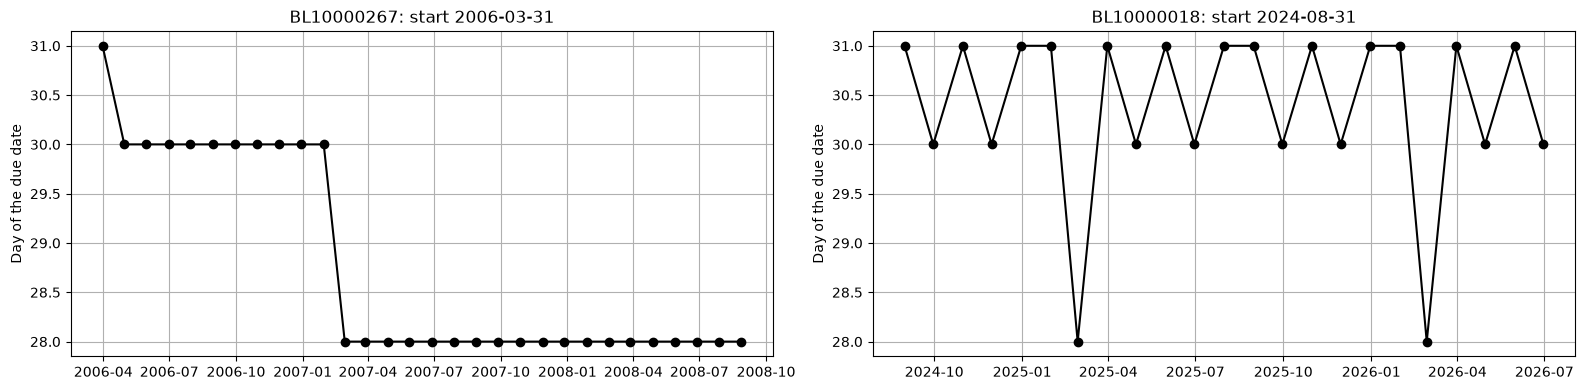

In [11]:
premium_items = data.table('NRPREM')
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 4))
for ax, policy_id in zip(axes, ['BL10000267', 'BL10000018']):
    items = premium_items[premium_items.PR_POLNR == policy_id].head(30)
    ax.plot(items.PR_DUEDT, items.PR_DUEDT.dt.day, marker='o', color='black')
    ax.set_title(f'{policy_id}: start {policies.loc[policy_id].PH_BEGDT.date()}')
    ax.set_ylabel('Day of the due date')
    ax.grid()
plt.tight_layout()
plt.show()

Left: a COBOL policy drifts 31 -> 30 -> 28 and stays on the 28th, also after the conversion (Neuron NG took the
last COBOL due date as its new anchor). Right: a Neuron NG policy always returns to the 31st.

`schedule.due_dates` implements both regimes. Checked on the whole premium history, every past due date of all
3,250 regular-premium policies is in the calculated schedule.

In [12]:
conversion = data.table('NREVNT').query('EV_EVTTP == 800').EV_EFFDT.min().date()
first_versions = data.table('NRPOLH').sort_values('PH_VRSNR').drop_duplicates('PH_POLNR').set_index('PH_POLNR')
first_versions = first_versions[first_versions.PH_FREQ.isin(list(FREQUENCY_MONTHS))]
history = premium_items.groupby('PR_POLNR').PR_DUEDT.apply(lambda dates: set(dates.dt.date))

missing = 0
for policy in first_versions.itertuples():
    schedule = set(due_dates(policy.PH_BEGDT.date(), policy.PH_ENDDT.date(), FREQUENCY_MONTHS[policy.PH_FREQ],
                             conversion, extract_date))
    missing += not history.get(policy.Index, set()) <= schedule
print('policies with a past due date outside the calculated schedule:', missing, 'of', len(first_versions))

policies with a past due date outside the calculated schedule: 0 of 3250


# Score

In [13]:
calculated = next_due_dates(data, extract_date)
target = {(row.policy_id, row.n): (row.due_date.date(), row.collection_date.date()) for row in targets_t1.itertuples()}
right = sum(calculated.get(key) == value for key, value in target.items())
print(f't1: {right} of {len(target)} right, {len(calculated)} calculated')

t1: 15028 of 15028 right, 20033 calculated


# Summary

| Task | Rule | Train accuracy |
|---|---|---|
| t0 | Paid items only; broker of the policy version on the money date; `NRCOMR` rate by tier and premium type; half up to the cent | 99.996 % (the 10 misses are manual corrections) |
| t1 | COBOL schedule (previous due + period) until the conversion 2007-08-11, then anchored; LS collected on the next business day, UB on the due date | 100 % |